# plot_HS_PRECT — CESM2 MA-GAUSS precipitation uncertainty partition

Python port merging `plot_HS_p.m` (global + EU-JJA precipitation change and
partition) with `plot_regions_P.m` (per-IPCC-continental-region partition),
which shared a MATLAB workspace.

Mirrors `plot_HS_TREFHT` but for `PRECT` (m s⁻¹ → mm/day via
`fact = 86400·10³`). The baseline is `PRECT` for member 1 and `PRECC+PRECL`
for members 2–3 (member 3's first 60 months are NaN), exactly as in the
MATLAB. Region means are vectorised over the polygon mask.

In [1]:
import sys, os, glob
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import mat_utils as mu
from mat_utils import brewermap, movmean, shaperead, inpolygon

fold = "/Volumes/D_Visioni2/CESM2_MA/MA_GAUSS/"
fold2 = "/Volumes/D_Visioni2/CESM2_MA/"
nam = "b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg."
exp = ["feedback_30N_30S", "feedback_15N_15S", "feedback_0N_1.0", "feedback_60N_60S_1.0",
       "SSP245-MA-GAUSS-DEFAULT", "SSP245-MA-GAUSS-LOWER-0.5", "SSP245-MA-GAUSS-LOWER-1.0"]
exp2 = ["1.0 above PI - 30-30", "1.0 above PI - 15-15", "1.0 above PI - EQ",
        "1.0 above PI - 60-60", "1.5 above PI - MS", "1.0 above PI - MS", "0.5 above PI - MS"]
ids = ".cam.h0."
ens = ["001", "002", "003"]
nums = [3, 3, 3, 3, 3, 3, 3]
fact = 86400 * 1e3

## Read MA-GAUSS PRECT ensemble and assemble the baseline (PRECT / PRECC+PRECL)

In [2]:
ta = None
for ix, ex in enumerate(exp):
    for ie, en in enumerate(ens):
        f = sorted(glob.glob(f"{fold}{nam}{ex}.{en}{ids}PRECT*.nc"))[0]
        t = mu.ncread(f, "PRECT")[:, :, 0:420].astype(np.float32)
        if ta is None:
            ta = np.empty(t.shape + (7, 3), dtype=np.float32)
        ta[:, :, :, ix, ie] = t
lat = mu.ncread(f, "lat").ravel(); lon = mu.ncread(f, "lon").ravel()

shp = ta.shape[:2]
# MATLAB auto-fills *unassigned* array elements with 0 (not NaN). The MATLAB
# script assigns b3 (PRECL) only for members 2-3, so b3 member 1 is 0 there,
# giving b1 member1 = PRECT + 0. Initialising with NaN instead would make the
# whole member-1 baseline NaN and wipe out every ensemble-mean line. So init
# with zeros and set ONLY the explicit member-3 first-60-month NaNs.
b1 = np.zeros(shp + (1020, 3), dtype=np.float32)
# member 1: PRECT
b1[:, :, 0:600, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}PRECT.201501-206412.nc", "PRECT")
b1[:, :, 600:1020, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}PRECT.206501-209912.nc", "PRECT")
# member 2/3: PRECC + PRECL
b1[:, :, 0:600, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECC.201501-206412.nc", "PRECC")
b1[:, :, 600:1008, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECC.206501-209812.nc", "PRECC")
b1[:, :, 0:60, 2] = np.nan      # MATLAB b1(:,:,1:60,3) = NaN
b1[:, :, 60:660, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECC.202001-206912.nc", "PRECC")
b1[:, :, 660:1020, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECC.207001-209912.nc", "PRECC")
b3 = np.zeros(shp + (1020, 3), dtype=np.float32)
b3[:, :, 0:600, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECL.201501-206412.nc", "PRECL")
b3[:, :, 600:1008, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECL.206501-209812.nc", "PRECL")
b3[:, :, 0:60, 2] = np.nan      # MATLAB b3(:,:,1:60,3) = NaN
b3[:, :, 60:660, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECL.202001-206912.nc", "PRECL")
b3[:, :, 660:1020, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECL.207001-209912.nc", "PRECL")
b1 = b1 + b3

## Global and EU-band annual / JJA means (×fact → mm/day)

In [3]:
ww = np.cos(lat / 180 * np.pi)
lm, lM = 128, 171
ta_zm = np.nanmean(ta, axis=0); tab_zm = np.nanmean(b1, axis=0)
ta_gm = (ta_zm * ww[:, None, None, None]).sum(0) / ww.sum()
ta_reg = (ta_zm[lm:lM] * ww[lm:lM, None, None, None]).sum(0) / ww[lm:lM].sum()
tab_gm = (tab_zm * ww[:, None, None]).sum(0) / ww.sum()
tab_reg = (tab_zm[lm:lM] * ww[lm:lM, None, None]).sum(0) / ww[lm:lM].sum()


def annual(x, n):
    return np.reshape(x, (12, n) + x.shape[1:], order="F").mean(axis=0)


ta_gm_y = annual(ta_gm, 35) * fact
tab_gm_y = annual(tab_gm, 85) * fact
ta_reg_y = np.reshape(ta_reg * fact, (12, 35, 7, 3), order="F")[5:8].mean(0)   # JJA
tab_reg_y = np.reshape(tab_reg * fact, (12, 85, 3), order="F")[5:8].mean(0)

/var/folders/t9/vl6_0lmn7w759j1nh0z6rblh0000gt/T/ipykernel_19171/3532265436.py:3: RuntimeWarning: Mean of empty slice
  ta_zm = np.nanmean(ta, axis=0); tab_zm = np.nanmean(b1, axis=0)


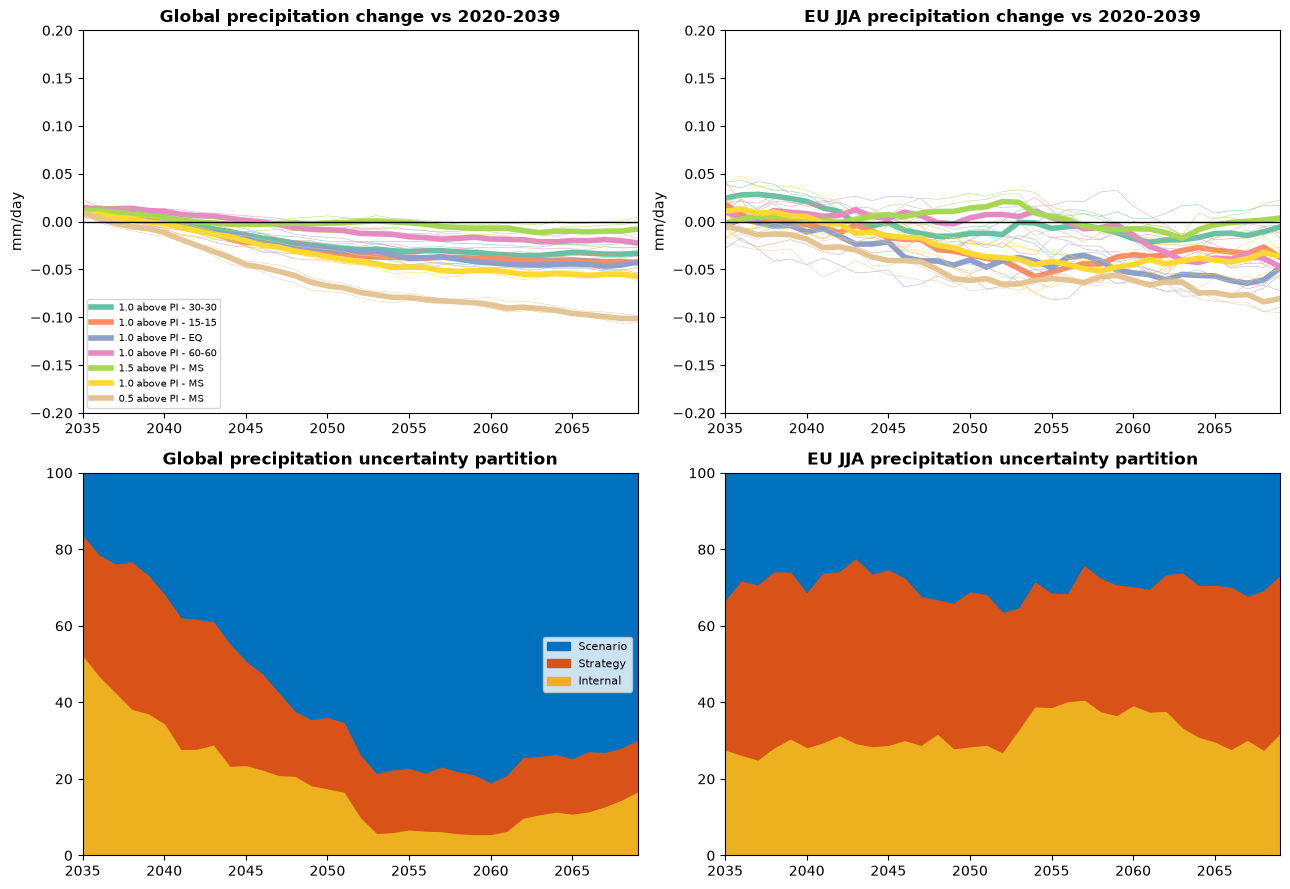

In [4]:
def partition(y):
    iv = np.std(y[:, 4, :], axis=1, ddof=1) ** 2
    sv = np.std(y[:, [0, 1, 2, 3, 5], 0], axis=1, ddof=1) ** 2
    cv = np.std(y[:, 4:7, 0], axis=1, ddof=1) ** 2
    return iv, sv, cv


fc = brewermap(7, "Set2")
AREA_C = [(0, 0.4470, 0.7410), (0.8500, 0.3250, 0.0980), (0.9290, 0.6940, 0.1250)]
time = np.arange(2035, 2070)
ref = slice(5, 25)


def cooling_panel(ax, y, yb, title):
    for ix in range(7):
        for ie in range(nums[ix]):
            ax.plot(time, movmean(y[:, ix, ie] - yb[ref, ie].mean(), 10), color=fc[ix], linewidth=.3)
        ax.plot(time, np.mean(movmean(y[:, ix, :] - yb[ref, :].mean(0), 10), axis=1),
                color=fc[ix], linewidth=4, label=exp2[ix])
    ax.plot([2035, 2070], [0, 0], "k", linewidth=1)
    ax.set_title(title, fontweight="bold"); ax.set_xlim(2035, 2069); ax.set_ylim(-.2, .2)
    ax.set_ylabel("mm/day")


def partition_panel(ax, y, title):
    iv, sv, cv = partition(y); tot = iv + sv + cv
    ax.fill_between(time, movmean((sv + iv + cv) / tot * 100, 10), 0, color=AREA_C[0], label="Scenario")
    ax.fill_between(time, movmean((sv + iv) / tot * 100, 10), 0, color=AREA_C[1], label="Strategy")
    ax.fill_between(time, movmean(iv / tot * 100, 10), 0, color=AREA_C[2], label="Internal")
    ax.set_xlim(2035, 2069); ax.set_ylim(0, 100); ax.set_title(title, fontweight="bold")


fig1, axs = plt.subplots(2, 2, figsize=(13, 9))
cooling_panel(axs[0, 0], ta_gm_y, tab_gm_y, "Global precipitation change vs 2020-2039")
axs[0, 0].legend(fontsize=7, loc="lower left")
cooling_panel(axs[0, 1], ta_reg_y, tab_reg_y, "EU JJA precipitation change vs 2020-2039")
partition_panel(axs[1, 0], ta_gm_y, "Global precipitation uncertainty partition")
axs[1, 0].legend(fontsize=8, loc="center right")
partition_panel(axs[1, 1], ta_reg_y, "EU JJA precipitation uncertainty partition")
fig1.tight_layout(); plt.show()

## Per-IPCC-continental-region partition (merged from plot_regions_P)

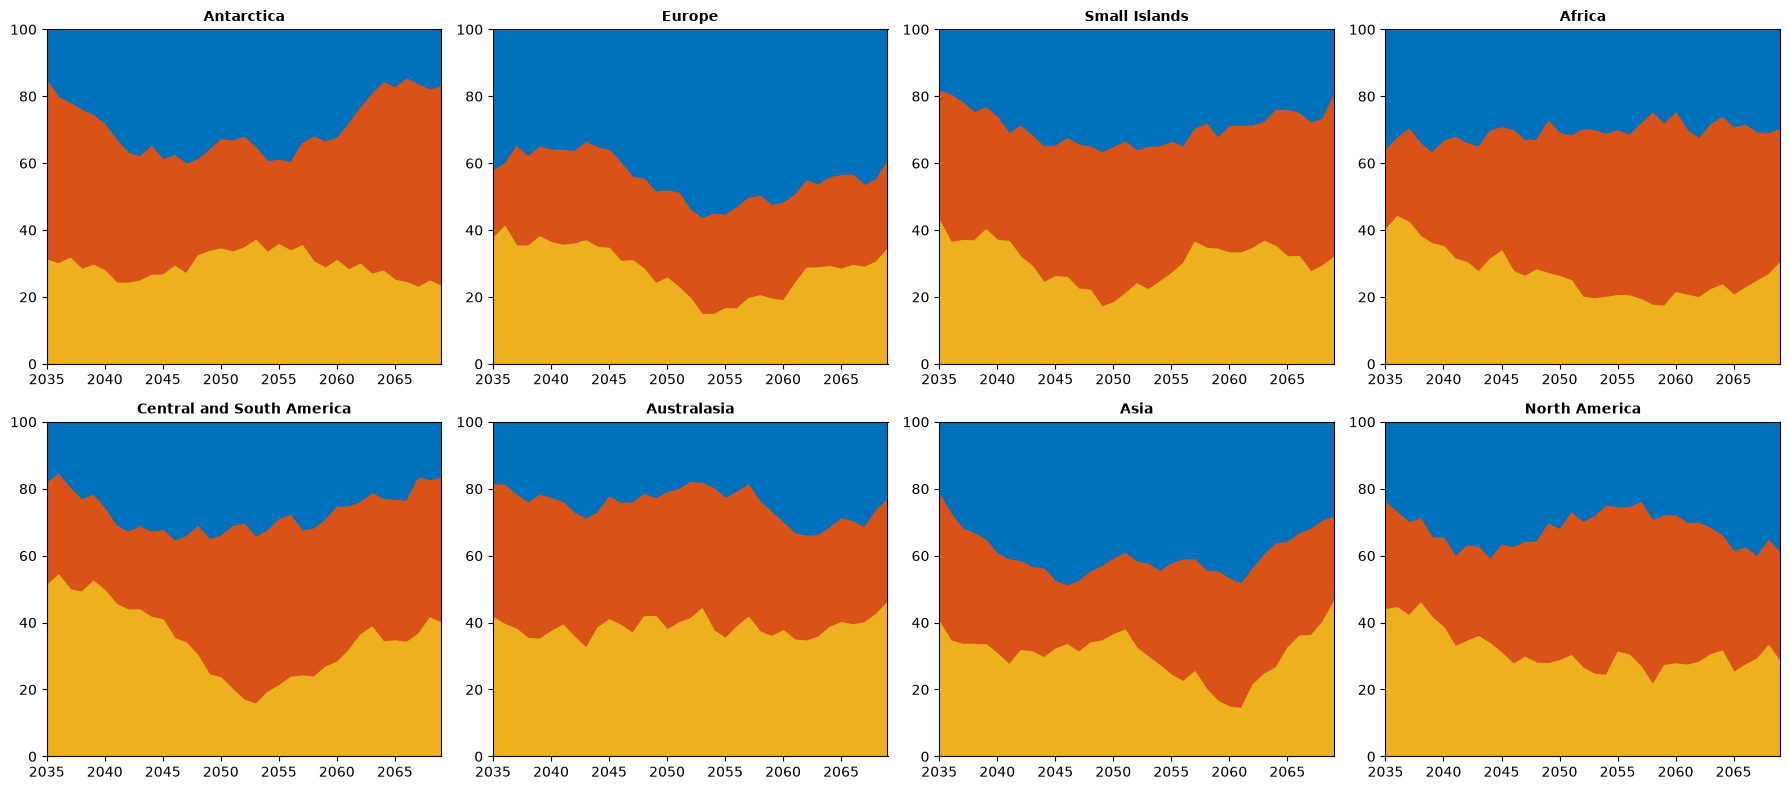

In [5]:
regions = shaperead("IPCC_WGII_continental_regions.shx")
latM, lonM = np.meshgrid(lat, lon - 180)
fig2, axes = plt.subplots(2, 4, figsize=(18, 8))
for fidx in range(8):
    ind = inpolygon(latM, lonM, regions[fidx].Y, regions[fidx].X)
    ta_reg_f = np.nanmean(ta[ind], axis=0) * fact
    ta_reg_yf = np.reshape(ta_reg_f, (12, 35, 7, 3), order="F").mean(0)
    iv, sv, cv = partition(ta_reg_yf); tot = iv + sv + cv
    ax = axes.ravel()[fidx]
    ax.fill_between(time, movmean((sv + iv + cv) / tot * 100, 10), 0, color=AREA_C[0])
    ax.fill_between(time, movmean((sv + iv) / tot * 100, 10), 0, color=AREA_C[1])
    ax.fill_between(time, movmean(iv / tot * 100, 10), 0, color=AREA_C[2])
    ax.set_xlim(2035, 2069); ax.set_ylim(0, 100)
    ax.set_title(regions[fidx].Region, fontweight="bold", fontsize=10)
fig2.tight_layout(); plt.show()

In [6]:
os.makedirs("py_outputs", exist_ok=True)
fig1.savefig("py_outputs/HS_plot_PRECT.png", dpi=300, bbox_inches="tight")
fig2.savefig("py_outputs/HS_plot_PRECT_regions.png", dpi=300, bbox_inches="tight")
print("done")

done
